<a href="https://colab.research.google.com/github/Babsali/Babsali/blob/main/cbt_readiness_grouped_cv.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CBT readiness: respondent-grouped verification and model comparison

The reviewed file `cbt_respondents_thesis_data.csv` was generated by the administrator export from the local SQLite database. The live database has now been backed up and aligned to the uploaded CSV: 314 matching attempts from 21 respondents, with no post-October-16 attempts remaining.

The notebook validates the eight predictor fields and their implementation formulas, checks terminal score/label agreement at the 50% threshold, reconciles inclusion and exclusion counts, and requires explicit database lineage dispositions for every modelling row before running grouped cross-validation. It reports pooled and fold-level results, confusion matrices, and the Ready/At-Risk recall trade-off. Model eligibility and ranking use the same risk-recall gate and settings as the application trainer.

The 90 complete labelled rows are from 18 respondents. Database review found attempt 298 has no earlier eligible same-subject assessment; 88 of the other 89 stored feature vectors differ from recomputation using the current application function. These differences do not by themselves prove terminal leakage, but feature provenance remains unconfirmed. Final model results are blocked until the source vectors are verified or excluded. This notebook evaluates the dataset experiment only; application integration and evaluation are separate.

## 1. Load the verified dataset artifacts

Run `scripts/build_verified_readiness_dataset.py` first. In a local notebook kernel, the notebook finds the generated files under `instance/models/training_archive/`. In Colab, upload the generated dataset CSV, exclusions CSV, and manifest JSON together. The notebook verifies their hashes before analysis.

In [1]:
import hashlib
import importlib
import json
from pathlib import Path

DATASET_NAME = 'verified_terminal_readiness_dataset.csv'
EXCLUSIONS_NAME = 'verified_terminal_readiness_exclusions.csv'
MANIFEST_NAME = 'verified_terminal_readiness_manifest.json'
artifact_names = {DATASET_NAME, EXCLUSIONS_NAME, MANIFEST_NAME}

try:
    colab_files = importlib.import_module('google.colab.files')
except ModuleNotFoundError:
    workspace_candidates = [Path.cwd(), *Path.cwd().parents]
    artifact_dir = next((
        root / 'instance' / 'models' / 'training_archive'
        for root in workspace_candidates
        if (root / 'instance' / 'models' / 'training_archive' / MANIFEST_NAME).is_file()
    ), None)
    if artifact_dir is None:
        raise FileNotFoundError(
            'Verified dataset artifacts were not found. Run scripts/build_verified_readiness_dataset.py first.'
        )
    artifact_paths = {name: artifact_dir / name for name in artifact_names}
else:
    uploaded = colab_files.upload()
    uploaded_names = set(uploaded)
    if uploaded_names != artifact_names:
        raise ValueError(
            f'Upload exactly these three artifacts: {sorted(artifact_names)}; received {sorted(uploaded_names)}.'
        )
    artifact_paths = {name: Path(name) for name in artifact_names}

CSV_PATH = artifact_paths[DATASET_NAME]
EXCLUSIONS_PATH = artifact_paths[EXCLUSIONS_NAME]
MANIFEST_PATH = artifact_paths[MANIFEST_NAME]
with MANIFEST_PATH.open(encoding='utf-8') as manifest_file:
    DATA_MANIFEST = json.load(manifest_file)

for artifact_name, key in (
    (DATASET_NAME, 'dataset_sha256'),
    (EXCLUSIONS_NAME, 'exclusions_sha256'),
):
    actual_hash = hashlib.sha256(artifact_paths[artifact_name].read_bytes()).hexdigest()
    if actual_hash != DATA_MANIFEST[key]:
        raise ValueError(f'Artifact hash mismatch for {artifact_name}. Rebuild and upload all three files together.')

print('Verified dataset:', CSV_PATH.name)
print('CSV SHA-256:', DATA_MANIFEST['dataset_sha256'])
print('Source database SHA-256:', DATA_MANIFEST['source_database_sha256'])
print('Included / excluded rows:', DATA_MANIFEST['included_rows'], '/', DATA_MANIFEST['excluded_rows'])

Saving verified_terminal_readiness_dataset.csv to verified_terminal_readiness_dataset.csv
Saving verified_terminal_readiness_exclusions.csv to verified_terminal_readiness_exclusions.csv
Saving verified_terminal_readiness_manifest.json to verified_terminal_readiness_manifest.json
Verified dataset: verified_terminal_readiness_dataset.csv
CSV SHA-256: 3a445deeeb4097c124ba2c38a57337172fbc7f22c2342333cb89e8eed8be52ad
Source database SHA-256: 6d78c7ac405a7a1566a5765d3def386f72b9a75d501d7b108ade2e92c92221b1
Included / excluded rows: 90 / 6


## 2. Install/import dependencies and define the analysis

The experiment uses scikit-learn, pandas, and matplotlib. Its grouped splitter, random seed, and candidate settings are recorded below. The settings mirror the repository’s thesis-analysis experiment; the application's production-training route uses a different Random Forest estimator count.

In [2]:
%pip -q install scikit-learn==1.6.1 pandas==2.3.2 scipy==1.18.0 matplotlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

RANDOM_STATE = 42
REQUESTED_FOLDS = 5
AT_RISK_RECALL_GATE = 0.80
FEATURES = [
    'avg_response_time_sec',
    'revision_rate',
    'accuracy_easy',
    'accuracy_medium',
    'accuracy_hard',
    'time_management_score',
    'completion_rate',
    'consistency_score',
]
TARGET = 'terminal_label'
GROUP = 'respondent_anon_id'
REQUIRED_COLUMNS = [
    'terminal_attempt_id', GROUP, 'subject', 'terminal_score_percent', TARGET,
    'source_attempt_ids_json', 'source_attempt_completed_at_json', *FEATURES,
]

MODELS = {
    'Logistic Regression': Pipeline([
        ('scaler', StandardScaler()),
        ('classifier', LogisticRegression(
            max_iter=1000, random_state=RANDOM_STATE, class_weight='balanced'
        )),
    ]),
    'Decision Tree': Pipeline([
        ('scaler', StandardScaler()),
        ('classifier', DecisionTreeClassifier(
            max_depth=10, random_state=RANDOM_STATE, class_weight='balanced'
        )),
    ]),
    'Random Forest': Pipeline([
        ('scaler', StandardScaler()),
        ('classifier', RandomForestClassifier(
            n_estimators=200,
            random_state=RANDOM_STATE,
            class_weight='balanced',
        )),
    ]),
}

print('scikit-learn:', __import__('sklearn').__version__)
print('pandas:', pd.__version__)
print('Random state:', RANDOM_STATE)
print('Requested folds:', REQUESTED_FOLDS)
print('At-Risk recall eligibility threshold:', AT_RISK_RECALL_GATE)
print('Random Forest settings: n_estimators=200, max_depth=None, class_weight=balanced')

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 2.3.2 which is incompatible.
scikit-learn: 1.6.1
pandas: 2.3.2
Random state: 42
Requested folds: 5
At-Risk recall eligibility threshold: 0.8
Random Forest settings: n_estimators=200, max_depth=None, class_weight=balanced


## 3. Source, cohort reconciliation, and target audit

The export route emits one row per `MockAttempt` from the local SQLite database. It includes the attempt ID and explicit terminal flag; score/timestamps come from the attempt, while predictors and optional labels come from the linked `MLFeatureRecord`. The export does not store all source-attempt IDs that generated a terminal feature vector.

The reviewed cohort reconciliation is 314 attempts across 21 respondent IDs: 114 Trial 1, 102 Trial 2, 96 Terminal, and 2 Trial Exam rows. The expected terminal cohort is 96 rows; three have no valid score-derived label, and three additional validly labelled rows have all eight predictors missing. Thus 93 valid score/label pairs minus 3 complete-case exclusions yields 90 complete labelled rows from 18 respondents. This cell recomputes the counts and requires them to match before analysis. Any difference must be investigated rather than silently treated as the same dataset.

No imputation is performed. A modelling record must have a finite terminal score, a label agreeing with `score_percent >= 50`, all eight finite feature values, and a respondent group. Rows with missing scores/labels and feature-driven exclusions are counted separately. Rows without an earlier same-subject non-terminal attempt visible in the export are listed by attempt ID and block evaluation until their database lineage is verified or they are explicitly excluded.

In [3]:
raw = pd.read_csv(CSV_PATH, dtype={GROUP: 'string'})
exclusions = pd.read_csv(EXCLUSIONS_PATH)
missing_dataset_columns = sorted(set(REQUIRED_COLUMNS) - set(raw.columns))
if missing_dataset_columns:
    raise ValueError(f'Verified dataset is missing columns: {missing_dataset_columns}')
if 'exclusion_reason' not in exclusions or 'terminal_attempt_id' not in exclusions:
    raise ValueError('Exclusion audit is missing required lineage columns.')

raw[GROUP] = raw[GROUP].astype('string').str.strip().replace('', pd.NA)
raw['terminal_attempt_id'] = pd.to_numeric(raw['terminal_attempt_id'], errors='coerce')
raw['terminal_score_percent'] = pd.to_numeric(raw['terminal_score_percent'], errors='coerce')
raw[TARGET] = pd.to_numeric(raw[TARGET], errors='coerce')
raw['terminal_completed_at_parsed'] = pd.to_datetime(
    raw['terminal_completed_at'], errors='coerce', utc=True
)
for feature in FEATURES:
    raw[feature] = pd.to_numeric(raw[feature], errors='coerce')

raw['derived_label'] = (raw['terminal_score_percent'] >= 50).astype(int)
raw['label_conflict'] = raw[TARGET].ne(raw['derived_label'])
raw['all_features_finite'] = np.isfinite(raw[FEATURES]).all(axis=1)
raw['group_valid'] = raw[GROUP].notna()
label_conflicts = int(raw['label_conflict'].sum())
if label_conflicts:
    raise ValueError(f'{label_conflicts} included labels disagree with the 50% terminal-score threshold.')
if not raw['all_features_finite'].all() or not raw['group_valid'].all():
    raise ValueError('Verified dataset contains missing/non-finite features or respondent groups.')
if raw['terminal_attempt_id'].isna().any() or raw['terminal_attempt_id'].duplicated().any():
    raise ValueError('Terminal attempt IDs must be present and unique.')

complete = raw.copy()
complete[TARGET] = complete[TARGET].astype(int)
complete['attempt_id'] = complete['terminal_attempt_id'].astype(int)
complete['score_percent'] = complete['terminal_score_percent']
complete['completed_at'] = complete['terminal_completed_at']

observed_counts = {
    'source_attempts': DATA_MANIFEST['source_attempt_count'],
    'source_respondents': DATA_MANIFEST['source_respondent_count'],
    'terminal_candidates': DATA_MANIFEST['source_terminal_attempt_count'],
    'valid_score_label_pairs': DATA_MANIFEST['valid_score_label_count'],
    'model_rows': len(complete),
    'model_respondents': complete[GROUP].nunique(),
}
expected_counts = {
    'source_attempts': 314,
    'source_respondents': 21,
    'terminal_candidates': 96,
    'valid_score_label_pairs': 93,
    'model_rows': 90,
    'model_respondents': 18,
}
reconciliation = pd.DataFrame({
    'expected_reviewed_cohort': pd.Series(expected_counts),
    'observed_verified_build': pd.Series(observed_counts),
})
reconciliation['matches'] = reconciliation['expected_reviewed_cohort'].eq(
    reconciliation['observed_verified_build']
)
display(reconciliation)

invalid_score_count = int((exclusions['derived_label'].isna()).sum())
valid_label_exclusion_count = int(exclusions['derived_label'].isin([0, 1]).sum())
audited_counts = pd.Series({
    'Terminal rows without a valid score/label pair': (
        DATA_MANIFEST['source_terminal_attempt_count'] - DATA_MANIFEST['valid_score_label_count']
    ),
    'Excluded rows with invalid/missing score or completion': invalid_score_count,
    'Validly labelled rows excluded for missing prior features': valid_label_exclusion_count,
    'Included Ready rows (1)': int((complete[TARGET] == 1).sum()),
    'Included At-Risk rows (0)': int((complete[TARGET] == 0).sum()),
    'Included modelling rows': len(complete),
    'Unique respondents in modelling data': complete[GROUP].nunique(),
    'Label/score conflicts in included data': label_conflicts,
})
display(audited_counts.to_frame('Count'))
display(exclusions.groupby('exclusion_reason', dropna=False).size().rename('excluded_rows').to_frame())

if not reconciliation['matches'].all():
    raise ValueError('Verified build does not match the reviewed 314-attempt cohort; investigate before modelling.')
if len(complete) < 10 or complete[TARGET].nunique() != 2:
    raise ValueError('Insufficient verified records or target classes for evaluation.')

,expected_reviewed_cohort,observed_verified_build,matches
source_attempts,314,314,True
source_respondents,21,21,True
terminal_candidates,96,96,True
valid_score_label_pairs,93,93,True
model_rows,90,90,True
model_respondents,18,18,True


,Count
Terminal rows without a valid score/label pair,3
Excluded rows with invalid/missing score or completion,3
Validly labelled rows excluded for missing prior features,3
Included Ready rows (1),50
Included At-Risk rows (0),40
Included modelling rows,90
Unique respondents in modelling data,18
Label/score conflicts in included data,0


,excluded_rows
exclusion_reason,
missing_or_invalid_terminal_score_or_completion,3
no_earlier_completed_same_subject_nonterminal_attempt,3


## 4. Verify feature construction and temporal lineage

The eight predictors are the application's `ML_FEATURE_NAMES`. For a Terminal Mock, `compute_table_3_1_features()` selects completed, same-student, same-subject, timestamped, non-terminal attempts with `completed_at < terminal.completed_at`; it computes response, revision, difficulty accuracy, time management, completion, and consistency from those attempts, never from the terminal attempt itself. The verified build stores the eligible source attempt IDs and timestamps for every included vector, and the next cell checks those timestamps against the terminal completion time.

The original administrator CSV does not contain feature-source attempt IDs. The verified build therefore recomputes features from the current database, records source lineage, and places rows with no eligible prior attempt or usable response data in the exclusions file. The three excluded labelled records are not training examples.

In [4]:
lineage_errors = []
source_counts = []
for row in complete.itertuples(index=False):
    try:
        source_ids = json.loads(row.source_attempt_ids_json)
        source_times = json.loads(row.source_attempt_completed_at_json)
    except (TypeError, ValueError, json.JSONDecodeError):
        lineage_errors.append((int(row.attempt_id), 'invalid_source_lineage_json'))
        continue
    if not source_ids or len(source_ids) != len(source_times):
        lineage_errors.append((int(row.attempt_id), 'missing_or_misaligned_source_attempts'))
        continue
    terminal_time = pd.to_datetime(row.terminal_completed_at, errors='coerce', utc=True)
    parsed_source_times = pd.to_datetime(pd.Series(source_times), errors='coerce', utc=True)
    if pd.isna(terminal_time) or parsed_source_times.isna().any():
        lineage_errors.append((int(row.attempt_id), 'invalid_source_or_terminal_timestamp'))
        continue
    if not (parsed_source_times < terminal_time).all():
        lineage_errors.append((int(row.attempt_id), 'source_attempt_not_before_terminal'))
        continue
    source_counts.append(len(source_ids))

FEATURE_LINEAGE_CONFIRMED = not lineage_errors and len(source_counts) == len(complete)
LINEAGE_VERIFIED_ATTEMPT_IDS = set(complete['attempt_id'].astype(int))
LINEAGE_EXCLUDED_ATTEMPT_IDS = set(exclusions['terminal_attempt_id'].dropna().astype(int))
if set(complete['attempt_id'].astype(int)) & LINEAGE_EXCLUDED_ATTEMPT_IDS:
    raise ValueError('An attempt is both included and excluded in the verified build.')
print('Included vectors with non-empty, timestamp-ordered source attempt lineage:', len(source_counts), '/', len(complete))
print('Median prior attempts per included vector:', float(np.median(source_counts)) if source_counts else 0)
print('Feature lineage checks passed:', FEATURE_LINEAGE_CONFIRMED)
print('Excluded terminal attempts by reason:')
display(exclusions[['terminal_attempt_id', 'subject', 'terminal_score_percent', 'exclusion_reason']])
if lineage_errors:
    display(pd.DataFrame(lineage_errors, columns=['terminal_attempt_id', 'lineage_error']))
    raise ValueError('Source feature lineage checks failed; do not run model evaluation.')

Included vectors with non-empty, timestamp-ordered source attempt lineage: 90 / 90
Median prior attempts per included vector: 2.0
Feature lineage checks passed: True
Excluded terminal attempts by reason:


,terminal_attempt_id,subject,terminal_score_percent,exclusion_reason
0,219,Mathematics,NaN,missing_or_invalid_terminal_score_or_completion
1,256,Civic Education,NaN,missing_or_invalid_terminal_score_or_completion
2,158,Chemistry,30.0,no_earlier_completed_same_subject_nonterminal_...
3,155,Mathematics,32.0,no_earlier_completed_same_subject_nonterminal_...
4,281,Physics,NaN,missing_or_invalid_terminal_score_or_completion
5,298,Agricultural Science,32.0,no_earlier_completed_same_subject_nonterminal_...


## 5. Feature definitions and grouped folds

| Feature | How it is generated | Source and directionality |
|---|---|---|
| `avg_response_time_sec` | Mean non-negative seconds for answered responses with recorded timing | Prior non-terminal question responses only |
| `revision_rate` | Sum of revisions divided by answered responses, capped at 1 | Prior non-terminal response records only |
| `accuracy_easy` | Correct Easy responses divided by Easy response count; 0 if no such responses | Prior non-terminal responses only |
| `accuracy_medium` | Correct Medium responses divided by Medium response count; 0 if no such responses | Prior non-terminal responses only |
| `accuracy_hard` | Correct Hard responses divided by Hard response count; 0 if no such responses | Prior non-terminal responses only |
| `time_management_score` | Mean per-attempt score from used/allowed time: scaled up below 30%, linear to 100% by 80%, 1 through 100%, then decreases | Prior attempt duration and question-set duration (fallback 3,600 seconds) |
| `completion_rate` | Answered response count divided by all response rows, capped at 1 | Prior non-terminal response records only |
| `consistency_score` | `1 - coefficient_of_variation(response_times)`, bounded to [0, 1]; 1 for one timed response, 0 for none | Prior non-terminal timed responses only |

All terminal labels are derived from the terminal score and checked against the CSV label. The terminal attempt is not an input to any feature. An export-level prior-attempt match does not establish exact feature provenance; only database/source-record review can do that.

Each respondent is assigned wholly to one test fold using `StratifiedGroupKFold`. The actual fold count is the smaller of five and the minimum number of distinct respondent groups in either class. Evaluation stops unless every test fold contains both labels and has zero respondent overlap.

In [5]:
complete_ids = set(complete['attempt_id'].astype(int))
verified_ids = set(int(value) for value in LINEAGE_VERIFIED_ATTEMPT_IDS)
excluded_ids = set(int(value) for value in LINEAGE_EXCLUDED_ATTEMPT_IDS)
if not FEATURE_LINEAGE_CONFIRMED:
    raise RuntimeError(
        'Model evaluation is blocked: inspect and document the feature-source lineage for the '
        'modelling candidates, then set FEATURE_LINEAGE_CONFIRMED = True.'
    )
if verified_ids & excluded_ids:
    raise ValueError('A lineage record cannot be both verified and excluded.')
if complete_ids - (verified_ids | excluded_ids):
    raise RuntimeError(
        f'{len(complete_ids - (verified_ids | excluded_ids))} candidate row(s) lack an explicit '
        'lineage verification or exclusion by attempt_id.'
    )

model_data = complete.loc[~complete['attempt_id'].astype(int).isin(excluded_ids)].copy()
if len(model_data) < 10 or model_data[TARGET].nunique() != 2:
    raise ValueError('Insufficient lineage-approved records or target classes for evaluation.')
model_data = model_data.reset_index(drop=True)
X = model_data[FEATURES].astype(float)
y = model_data[TARGET].astype(int)
groups = model_data[GROUP].astype(str)

respondent_count = groups.nunique()
group_counts_by_class = model_data.groupby(TARGET)[GROUP].nunique()
n_splits = min(REQUESTED_FOLDS, int(group_counts_by_class.min()))
if n_splits < 2:
    raise ValueError('At least two distinct respondent groups per label are required.')

cv = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=RANDOM_STATE)
folds = list(cv.split(X, y, groups))
fold_audit = []
for fold_number, (train_index, test_index) in enumerate(folds, start=1):
    train_groups = set(groups.iloc[train_index])
    test_groups = set(groups.iloc[test_index])
    overlap = train_groups & test_groups
    test_classes = set(y.iloc[test_index])
    if overlap:
        raise AssertionError(f'Respondent leakage found in fold {fold_number}.')
    if test_classes != {0, 1}:
        raise ValueError(f'Fold {fold_number} does not contain both target classes.')
    fold_audit.append({
        'fold': fold_number,
        'train_rows': len(train_index),
        'train_respondents': len(train_groups),
        'test_rows': len(test_index),
        'test_respondents': len(test_groups),
        'At-Risk test rows': int((y.iloc[test_index] == 0).sum()),
        'Ready test rows': int((y.iloc[test_index] == 1).sum()),
        'respondent_overlap': len(overlap),
    })

print('Lineage-approved model rows:', len(model_data))
print('Unique respondents in modelling data:', respondent_count)
print('Ready / At-Risk rows:', int((y == 1).sum()), '/', int((y == 0).sum()))
print(f'Using {n_splits} respondent-grouped folds.')
display(pd.DataFrame(fold_audit).set_index('fold'))

Lineage-approved model rows: 90
Unique respondents in modelling data: 18
Ready / At-Risk rows: 50 / 40
Using 5 respondent-grouped folds.


,train_rows,train_respondents,test_rows,test_respondents,At-Risk test rows,Ready test rows,respondent_overlap
fold,,,,,,,
1,70,15,20,3,3,17,0
2,78,14,12,4,9,3,0
3,69,14,21,4,11,10,0
4,65,14,25,4,10,15,0
5,78,15,12,3,7,5,0


## 6. Evaluate and select candidates cautiously

Every reported prediction is out-of-fold, and each fold has a fresh pipeline so scaling is fit only on training respondents. Confusion matrices use actual labels as rows and predicted labels as columns, ordered At-Risk (`0`), Ready (`1`). Ready recall measures how many Ready students are identified; At-Risk recall measures how many At-Risk students are correctly flagged. These objectives trade off: predicting more students At-Risk can improve At-Risk recall while reducing Ready recall and increasing false alarms.

Model eligibility requires pooled out-of-fold At-Risk recall of at least 0.80, matching the application threshold. Among eligible models, rank by mean fold F1, then mean fold ROC-AUC, then mean fold accuracy, matching the application trainer. Pooled out-of-fold metrics are also reported but do not replace those fold-mean tie-breakers. If no model meets the risk-recall gate, report that no model is selected. Accuracy or ROC-AUC alone never determines selection.

In [6]:
def evaluate_model(estimator, X, y, groups, folds):
    oof_predictions = np.full(len(y), -1, dtype=int)
    oof_probabilities = np.full(len(y), np.nan, dtype=float)
    fold_details = []

    for fold_number, (train_index, test_index) in enumerate(folds, start=1):
        model = clone(estimator)
        model.fit(X.iloc[train_index], y.iloc[train_index])
        predictions = model.predict(X.iloc[test_index])
        ready_index = list(model.classes_).index(1)
        probabilities = model.predict_proba(X.iloc[test_index])[:, ready_index]
        actual = y.iloc[test_index]
        matrix = confusion_matrix(actual, predictions, labels=[0, 1])
        at_risk_recall = matrix[0, 0] / matrix[0].sum()
        ready_recall = matrix[1, 1] / matrix[1].sum()

        oof_predictions[test_index] = predictions
        oof_probabilities[test_index] = probabilities
        fold_details.append({
            'fold': fold_number,
            'test_rows': len(test_index),
            'test_respondents': groups.iloc[test_index].nunique(),
            'accuracy': accuracy_score(actual, predictions),
            'ready_precision': precision_score(actual, predictions, pos_label=1, zero_division=0),
            'ready_recall': ready_recall,
            'ready_f1': f1_score(actual, predictions, pos_label=1, zero_division=0),
            'at_risk_recall': at_risk_recall,
            'roc_auc': roc_auc_score(actual, probabilities),
            'confusion_matrix': matrix.tolist(),
        })

    if (oof_predictions < 0).any() or not np.isfinite(oof_probabilities).all():
        raise AssertionError('Some records did not receive exactly one out-of-fold prediction.')

    matrix = confusion_matrix(y, oof_predictions, labels=[0, 1])
    result = {
        'Accuracy': accuracy_score(y, oof_predictions),
        'Ready precision': precision_score(y, oof_predictions, pos_label=1, zero_division=0),
        'Ready recall': recall_score(y, oof_predictions, pos_label=1, zero_division=0),
        'Ready F1': f1_score(y, oof_predictions, pos_label=1, zero_division=0),
        'At-Risk recall': matrix[0, 0] / matrix[0].sum(),
        'ROC-AUC': roc_auc_score(y, oof_probabilities),
        'Fold accuracy mean': float(np.mean([row['accuracy'] for row in fold_details])),
        'Fold accuracy SD': float(np.std([row['accuracy'] for row in fold_details])),
        'Fold Ready recall mean': float(np.mean([row['ready_recall'] for row in fold_details])),
        'Fold Ready F1 mean': float(np.mean([row['ready_f1'] for row in fold_details])),
        'Fold At-Risk recall mean': float(np.mean([row['at_risk_recall'] for row in fold_details])),
        'Fold ROC-AUC mean': float(np.mean([row['roc_auc'] for row in fold_details])),
        'Confusion matrix [ [TN, FP], [FN, TP] ]': matrix.tolist(),
        'Fold details': fold_details,
        'OOF predictions': oof_predictions,
    }
    return result


results = {
    name: evaluate_model(model, X, y, groups, folds)
    for name, model in MODELS.items()
}
metric_columns = [
    'Accuracy', 'Ready precision', 'Ready recall', 'Ready F1', 'At-Risk recall',
    'ROC-AUC', 'Fold accuracy mean', 'Fold accuracy SD',
    'Fold Ready recall mean', 'Fold Ready F1 mean', 'Fold At-Risk recall mean',
    'Fold ROC-AUC mean',
]
metric_table = pd.DataFrame({
    name: {key: result[key] for key in metric_columns}
    for name, result in results.items()
}).T
display(metric_table.mul(100).round(2).astype(str).add('%'))

fold_result_rows = []
for model_name, result in results.items():
    for detail in result['Fold details']:
        fold_result_rows.append({'model': model_name, **detail})
fold_result_table = pd.DataFrame(fold_result_rows).set_index(['model', 'fold'])
display(fold_result_table)

for name, result in results.items():
    print(f"{name} pooled confusion matrix [ [TN, FP], [FN, TP] ]: "
          f"{result['Confusion matrix [ [TN, FP], [FN, TP] ]']}")
    print(f"{name} fold confusion matrices: "
          f"{[row['confusion_matrix'] for row in result['Fold details']]}")

eligible_models = [
    (name, result) for name, result in results.items()
    if result['At-Risk recall'] >= AT_RISK_RECALL_GATE
]
eligible_models.sort(
    key=lambda item: (
        item[1]['Fold Ready F1 mean'],
        item[1]['Fold ROC-AUC mean'],
        item[1]['Fold accuracy mean'],
    ),
    reverse=True,
)
selected_model = eligible_models[0][0] if eligible_models else None
selection_table = pd.DataFrame([
    {
        'model': name,
        'At-Risk recall': result['At-Risk recall'],
        'meets_0.80_gate': result['At-Risk recall'] >= AT_RISK_RECALL_GATE,
        'Ready recall': result['Ready recall'],
        'Fold Ready F1 mean': result['Fold Ready F1 mean'],
        'Fold ROC-AUC mean': result['Fold ROC-AUC mean'],
        'Fold accuracy mean': result['Fold accuracy mean'],
        'selected': name == selected_model,
    }
    for name, result in results.items()
]).sort_values(
    ['meets_0.80_gate', 'Fold Ready F1 mean', 'Fold ROC-AUC mean', 'Fold accuracy mean'],
    ascending=[False, False, False, False],
)
display(selection_table)
print('Notebook candidate selected:', selected_model or 'None; no model met the At-Risk recall gate')

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


,Accuracy,Ready precision,Ready recall,Ready F1,At-Risk recall,ROC-AUC,Fold accuracy mean,Fold accuracy SD,Fold Ready recall mean,Fold Ready F1 mean,Fold At-Risk recall mean,Fold ROC-AUC mean
Logistic Regression,86.67%,89.58%,86.0%,87.76%,87.5%,93.0%,88.01%,6.71%,82.67%,85.98%,85.88%,92.36%
Decision Tree,83.33%,87.23%,82.0%,84.54%,85.0%,83.5%,86.08%,10.52%,85.33%,86.27%,74.55%,79.94%
Random Forest,90.0%,90.2%,92.0%,91.09%,87.5%,95.1%,91.32%,7.9%,92.0%,91.59%,90.73%,98.56%


test_rows  test_respondents  accuracy  \
model               fold                                          
Logistic Regression 1            20                 3  0.950000   
                    2            12                 4  0.916667   
                    3            21                 4  0.857143   
                    4            25                 4  0.760000   
                    5            12                 3  0.916667   
Decision Tree       1            20                 3  0.850000   
                    2            12                 4  1.000000   
                    3            21                 4  0.857143   
                    4            25                 4  0.680000   
                    5            12                 3  0.916667   
Random Forest       1            20                 3  1.000000   
                    2            12                 4  1.000000   
                    3            21                 4  0.809524   
                    4            25                 4  0.840000   
                    5            12                 3  0.916667   

                          ready_precision  ready_recall  ready_f1  \
model               fold                                            
Logistic Regression 1            0.944444      1.000000  0.971429   
                    2            1.000000      0.666667  0.800000   
                    3            0.769231      1.000000  0.869565   
                    4            0.909091      0.666667  0.769231   
                    5            1.000000      0.800000  0.888889   
Decision Tree       1            0.850000      1.000000  0.918919   
                    2            1.000000      1.000000  1.000000   
                    3            0.769231      1.000000  0.869565   
                    4            1.000000      0.466667  0.636364   
                    5            1.000000      0.800000  0.888889   
Random Forest       1            1.000000      1.000000  1.000000   
                    2            1.000000      1.000000  1.000000   
                    3            0.714286      1.000000  0.833333   
                    4            0.923077      0.800000  0.857143   
                    5            1.000000      0.800000  0.888889   

                          at_risk_recall   roc_auc   confusion_matrix  
model               fold                                               
Logistic Regression 1           0.666667  1.000000  [[2, 1], [0, 17]]  
                    2           1.000000  0.777778   [[9, 0], [1, 2]]  
                    3           0.727273  0.900000  [[8, 3], [0, 10]]  
                    4           0.900000  0.940000  [[9, 1], [5, 10]]  
                    5           1.000000  1.000000   [[7, 0], [1, 4]]  
Decision Tree       1           0.000000  0.500000  [[0, 3], [0, 17]]  
                    2           1.000000  1.000000   [[9, 0], [0, 3]]  
                    3           0.727273  0.863636  [[8, 3], [0, 10]]  
                    4           1.000000  0.733333  [[10, 0], [8, 7]]  
                    5           1.000000  0.900000   [[7, 0], [1, 4]]  
Random Forest       1           1.000000  1.000000  [[3, 0], [0, 17]]  
                    2           1.000000  1.000000   [[9, 0], [0, 3]]  
                    3           0.636364  0.954545  [[7, 4], [0, 10]]  
                    4           0.900000  0.973333  [[9, 1], [3, 12]]  
                    5           1.000000  1.000000   [[7, 0], [1, 4]]

Logistic Regression pooled confusion matrix [ [TN, FP], [FN, TP] ]: [[35, 5], [7, 43]]
Logistic Regression fold confusion matrices: [[[2, 1], [0, 17]], [[9, 0], [1, 2]], [[8, 3], [0, 10]], [[9, 1], [5, 10]], [[7, 0], [1, 4]]]
Decision Tree pooled confusion matrix [ [TN, FP], [FN, TP] ]: [[34, 6], [9, 41]]
Decision Tree fold confusion matrices: [[[0, 3], [0, 17]], [[9, 0], [0, 3]], [[8, 3], [0, 10]], [[10, 0], [8, 7]], [[7, 0], [1, 4]]]
Random Forest pooled confusion matrix [ [TN, FP], [FN, TP] ]: [[35, 5], [4, 46]]
Random Forest fold confusion matrices: [[[3, 0], [0, 17]], [[9, 0], [0, 3]], [[7, 4], [0, 10]], [[9, 1], [3, 12]], [[7, 0], [1, 4]]]


,model,At-Risk recall,meets_0.80_gate,Ready recall,Fold Ready F1 mean,Fold ROC-AUC mean,Fold accuracy mean,selected
2,Random Forest,0.875,True,0.92,0.915873,0.985576,0.913238,True
1,Decision Tree,0.850,True,0.82,0.862747,0.799394,0.860762,False
0,Logistic Regression,0.875,True,0.86,0.859823,0.923556,0.880095,False


Notebook candidate selected: Random Forest


## 7. Plot pooled out-of-fold confusion matrices

These are pooled out-of-fold confusion matrices. Each respondent’s predictions come from a model that was not trained on that respondent’s records.

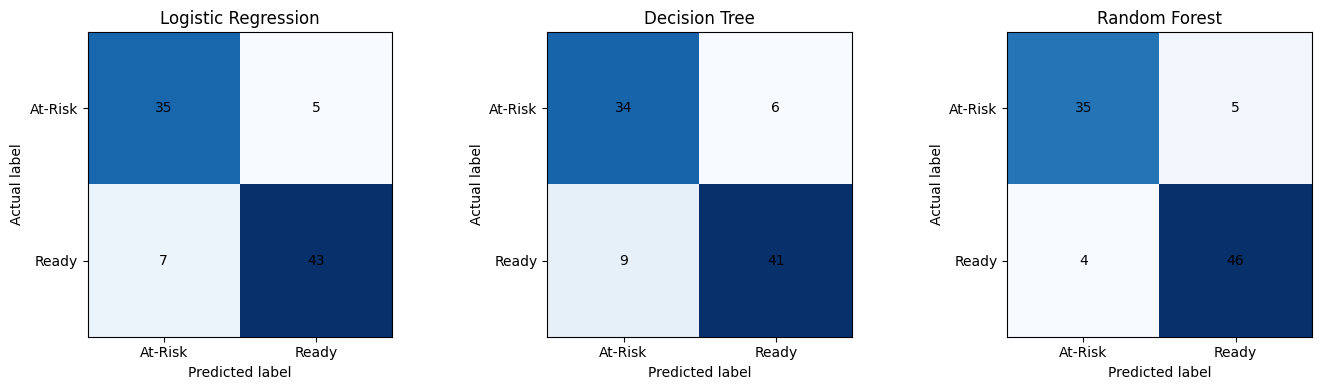

In [7]:
fig, axes = plt.subplots(1, len(results), figsize=(14, 4))
for axis, (name, result) in zip(axes, results.items()):
    matrix = np.asarray(result['Confusion matrix [ [TN, FP], [FN, TP] ]'])
    axis.imshow(matrix, cmap='Blues')
    axis.set_title(name)
    axis.set_xlabel('Predicted label')
    axis.set_ylabel('Actual label')
    axis.set_xticks([0, 1], labels=['At-Risk', 'Ready'])
    axis.set_yticks([0, 1], labels=['At-Risk', 'Ready'])
    for row in range(2):
        for column in range(2):
            axis.text(column, row, str(matrix[row, column]), ha='center', va='center')
plt.tight_layout()
plt.show()

## 8. Interpretation and reproducibility

This verified run uses 90 outcomes from 18 respondents (50 Ready, 40 At-Risk), with five respondent-grouped folds. The dataset SHA-256 is `3a445deeeb4097c124ba2c38a57337172fbc7f22c2342333cb89e8eed8be52ad`. Full fold audits, fold confusion matrices, and metrics are saved in `instance/models/training_archive/verified_terminal_readiness_cv_results.json`.

All three candidates pass the project-defined 80% pooled At-Risk recall gate. Random Forest ranks first by mean fold F1 (91.59%), then mean fold ROC-AUC (98.56%) and mean fold accuracy (91.32%). Its pooled results are 90.00% accuracy, 90.20% Ready precision, 92.00% Ready recall, 87.50% At-Risk recall, 91.09% Ready F1, and 95.10% ROC-AUC. The pooled confusion matrix is `[[35, 5], [4, 46]]` (actual rows, predicted columns; At-Risk then Ready). Five At-Risk outcomes were predicted Ready; four Ready outcomes were flagged At-Risk.

Results are exploratory, not stable estimates of school-wide performance: 18 independent respondents is a small validation base, and the folds have unequal class composition. The Random Forest's At-Risk recall also varied from 63.64% to 100.00% across folds. Logistic Regression emitted an `OptimizeWarning` about an unknown `iprint` option under Python 3.13.14, pandas 2.3.2, SciPy 1.18.0, and scikit-learn 1.6.1. Resolve or reproduce in a supported dependency environment before formal claims.

The selected Random Forest has been promoted through the application training route. Initial application smoke checks confirm the admin dashboard displays the same dataset fingerprint and that the production classifier/scaler return a valid prediction from eight named features. These checks do not replace full offline exam workflow, student review, persistence, and failure-mode evaluation; notebook cross-validation alone does not validate the application.